In [ ]:
import sys, site, importlib

!pip install --user -q nucleus-cdk==0.6.0rc1
!pip install --user -q pyarrow

user_site = site.getusersitepackages()
if user_site not in sys.path:
    sys.path.insert(0, user_site)
importlib.invalidate_caches()

import importlib.metadata as md
assert md.version("nucleus-cdk") == "0.6.0rc1", f"got {md.version('nucleus-cdk')}"

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from cdk import logging
log = logging.setup_logging(logging.INFO)

# Import the cdk platereader module
from cdk.instruments import platereader as pr

INFO:cdk.logging:Logging initialized


In [3]:
import sys
sys.path

['/content',
 '/env/python',
 '/usr/lib/python313.zip',
 '/usr/lib/python3.13',
 '/usr/lib/python3.13/lib-dynload',
 '',
 '/usr/local/lib/python3.13/dist-packages',
 '/usr/lib/python3/dist-packages',
 '/usr/local/lib/python3.13/dist-packages/IPython/extensions',
 '/root/.ipython']

In [ ]:
from cdk.analysis.cell import microscopy as m

## Load data

Will put a proper read parquet in the actual microscopy CDK code. Once that's done there's a load function that will also take a platemap (like the the platereader).

In [5]:
data = pd.read_parquet(
    "https://data.nucleus.engineering/microscopy/20260728_week2A-day3_TetR-final_2026-07-29_14-59-26.596376.parquet",
    storage_options={
        "User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 "
                      "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"
    }
)

# data = data.merge(platemap, on="Well")
# data = data.sort_values(by=["Experiment", "Name", "Timepoint"])

In [6]:
data.head()

,Label,Area (um^2),Diameter (Equivalent) (um),Diameter (Feret) (um),Length Major (um),Length Minor (um),Perimeter (um),Intensity Mean (GFP),Intensity Mean (Alexa Fluor 647),Intensity Max (GFP),...,Centroid.1,Volume (um^3),Circularity,Intensity Sum (GFP),Intensity Norm (GFP),Intensity Sum (Alexa Fluor 647),Intensity Norm (Alexa Fluor 647),Timepoint,Dataset,Well
0,1,3.437559,2.092089,2.536052,2.399149,1.849278,6.350666,61018.451613,790.548387,65534.0,...,203.699323,4.794453,1.071079,1891572,12726.885631,24507,164.888139,0,/data/microscopy/20260728_week2A-day3_TetR-fin...,M10
1,2,3.104892,1.988284,2.401297,2.264397,1.760943,5.798933,24236.142857,698.178571,44296.0,...,226.891929,4.115604,1.160273,678612,5888.842729,19549,169.641837,0,/data/microscopy/20260728_week2A-day3_TetR-fin...,M10
2,3,8.427564,3.275715,3.586520,3.445320,3.099106,9.761465,27365.960526,761.815789,52431.0,...,273.195829,18.404198,1.111430,2079813,1486.941241,57898,41.393589,0,/data/microscopy/20260728_week2A-day3_TetR-fin...,M10
3,4,3.659337,2.158521,2.536052,2.407244,1.929534,6.155599,18180.909091,620.212121,24191.0,...,362.889273,5.265837,1.213589,599970,3452.615251,20467,117.780350,0,/data/microscopy/20260728_week2A-day3_TetR-fin...,M10
4,5,6.875118,2.958661,3.279670,3.047197,2.884477,8.900398,6853.903226,618.854839,12014.0,...,300.946065,13.560760,1.090614,424942,505.421757,38369,45.635704,0,/data/microscopy/20260728_week2A-day3_TetR-fin...,M10


## Summary Plots

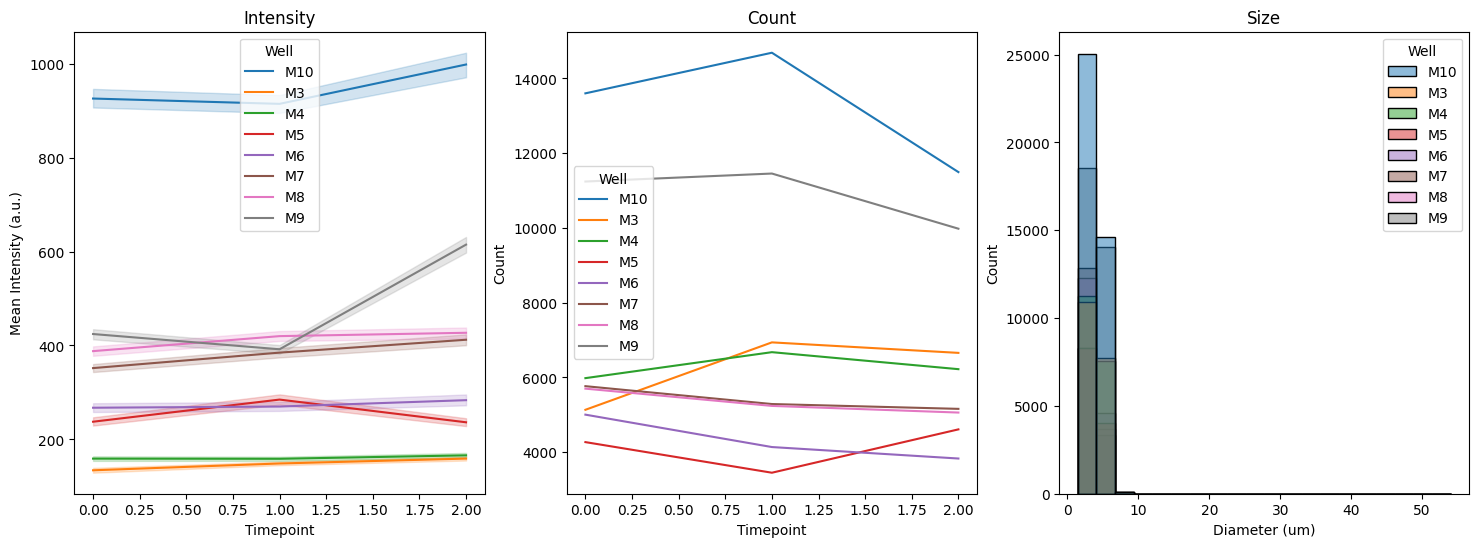

In [7]:
m.plot_summary(data)

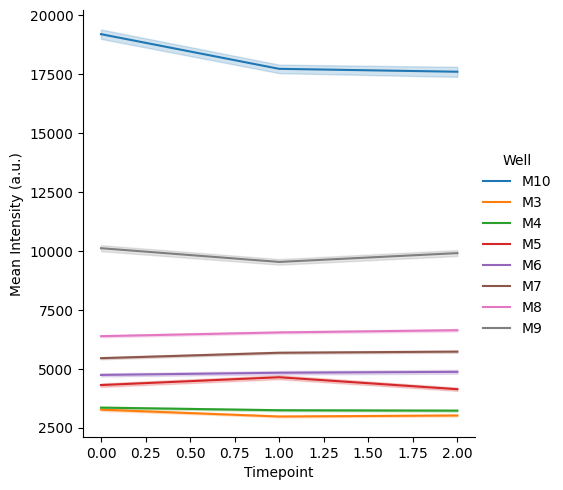

In [8]:
m.plot_intensity(data)

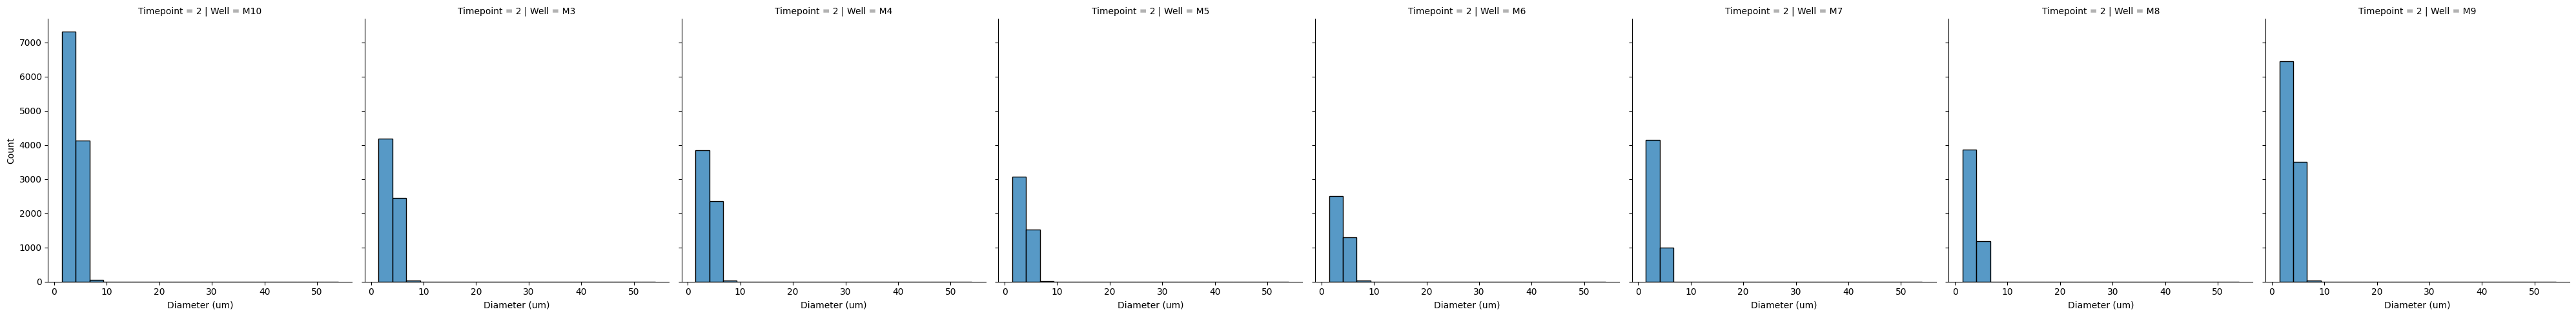

In [9]:
m.plot_size(data)

## Fogplots

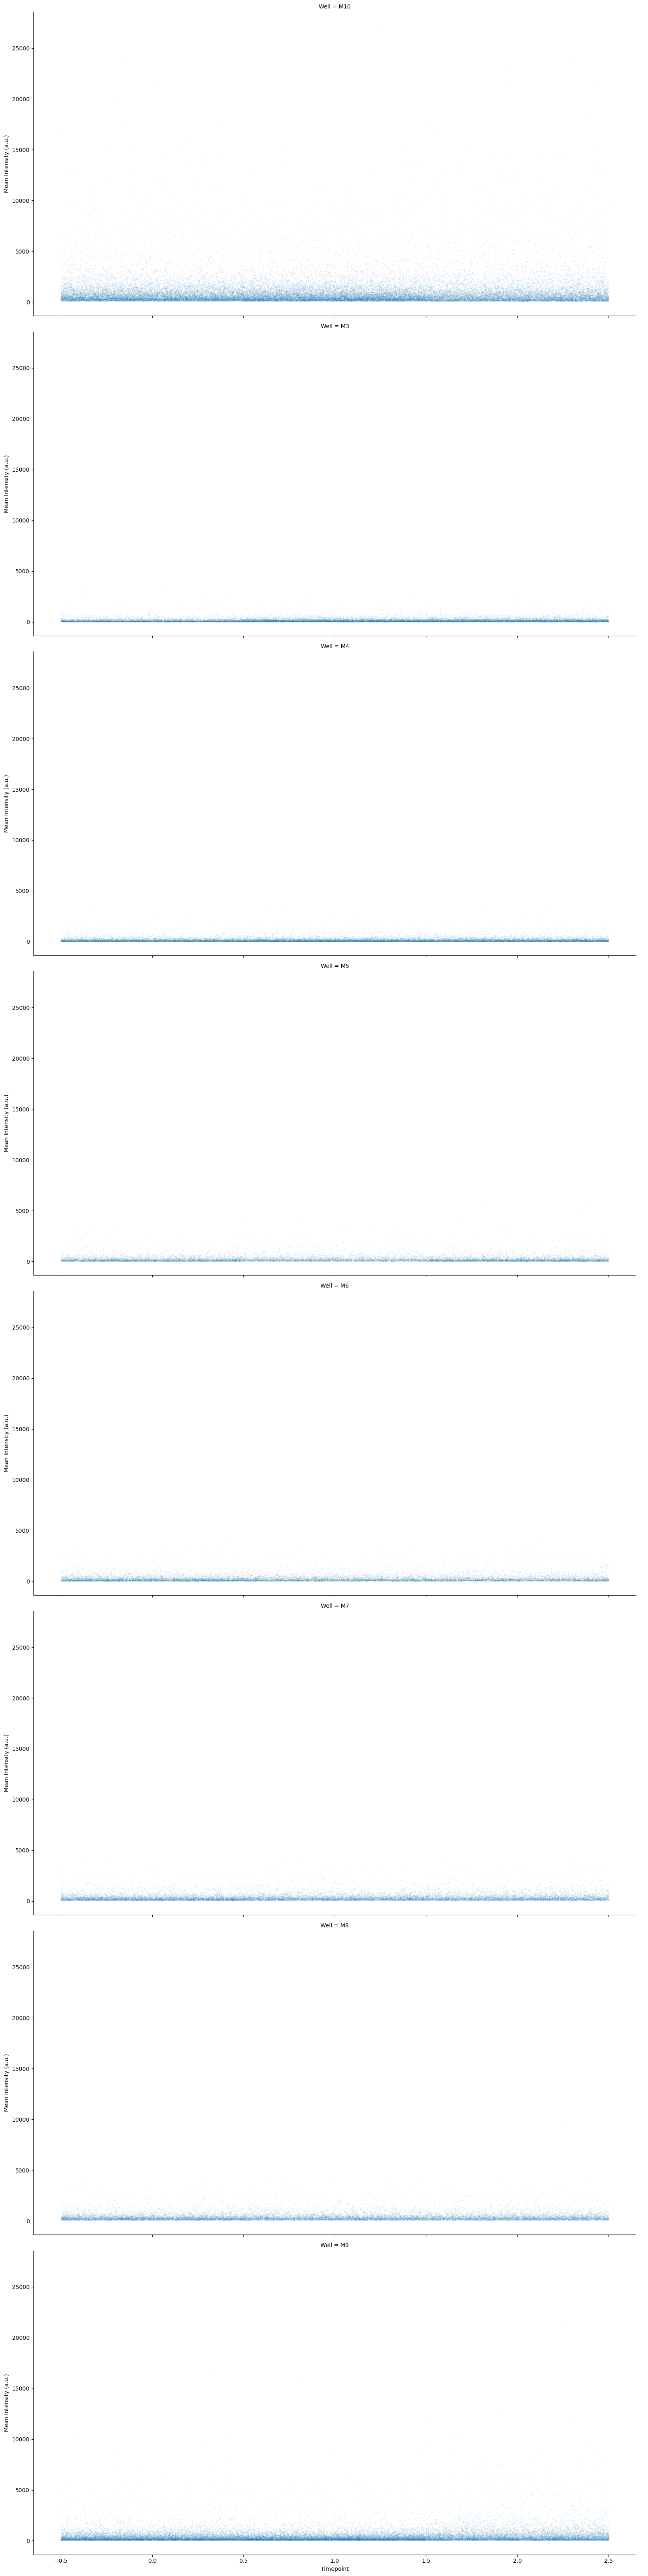

In [10]:
m.plot_fogplot(data)

## Plotting

In [11]:
last_timepoint = data['Timepoint'].max()

dye_leakage_data = data[data['Well'].isin(['M3','M4', 'M5', 'M6', 'M7', 'M8', 'M9','M10'])].copy()

# Filter for liposomes larger than 10 um in Diameter (Equivalent)
dye_leakage_data = dye_leakage_data[dye_leakage_data['Diameter (Equivalent) (um)'] > 5]

# Filter for the last time point
dye_leakage_data = dye_leakage_data[dye_leakage_data['Timepoint'] == last_timepoint]

# Pool K3 and K4 together as 'Neg Control', and K5 and K6 as 'Pos Control'
dye_leakage_data['Well'] = dye_leakage_data['Well'].replace({'M3': 'Neg Control', 'M4': 'Neg Control', 'M5': 'Pos Control', 'M6': 'Pos Control', 'M7': 'EXP_OFF', 'M8': 'EXP_OFF', 'M9': 'EXP_ON', 'M10': 'EXP_ON'})


In [12]:
dye_leakage_data.head()


,Label,Area (um^2),Diameter (Equivalent) (um),Diameter (Feret) (um),Length Major (um),Length Minor (um),Perimeter (um),Intensity Mean (GFP),Intensity Mean (Alexa Fluor 647),Intensity Max (GFP),...,Centroid.1,Volume (um^3),Circularity,Intensity Sum (GFP),Intensity Norm (GFP),Intensity Sum (Alexa Fluor 647),Intensity Norm (Alexa Fluor 647),Timepoint,Dataset,Well
28402,112,20.292687,5.083055,5.582097,5.365171,4.822600,16.192930,8449.448087,742.131148,55663.0,...,306.956852,68.765901,0.972520,1546249,122.872645,135810,10.792139,2,/data/microscopy/20260728_week2A-day3_TetR-fin...,EXP_ON
28514,224,20.292687,5.083055,5.661000,5.319363,4.889912,16.387997,23971.885246,1075.551913,55715.0,...,339.672738,68.765901,0.949506,4386855,348.601342,196826,15.640774,2,/data/microscopy/20260728_week2A-day3_TetR-fin...,EXP_ON
28519,229,22.621356,5.366787,6.003243,5.655242,5.096181,16.939729,13667.200980,945.676471,61795.0,...,690.059250,80.936003,0.990639,2788109,168.864294,192918,11.684250,2,/data/microscopy/20260728_week2A-day3_TetR-fin...,EXP_ON
28532,242,21.845133,5.273906,6.003243,5.487377,5.124148,17.524930,15623.923858,877.446701,26134.0,...,270.625888,76.806122,0.893824,3077913,203.420292,172857,11.424177,2,/data/microscopy/20260728_week2A-day3_TetR-fin...,EXP_ON
28533,243,19.849131,5.027196,5.690306,5.283933,4.813801,16.387997,9800.134078,849.854749,35438.0,...,305.286587,66.523647,0.928752,1754224,147.318053,152124,12.775228,2,/data/microscopy/20260728_week2A-day3_TetR-fin...,EXP_ON


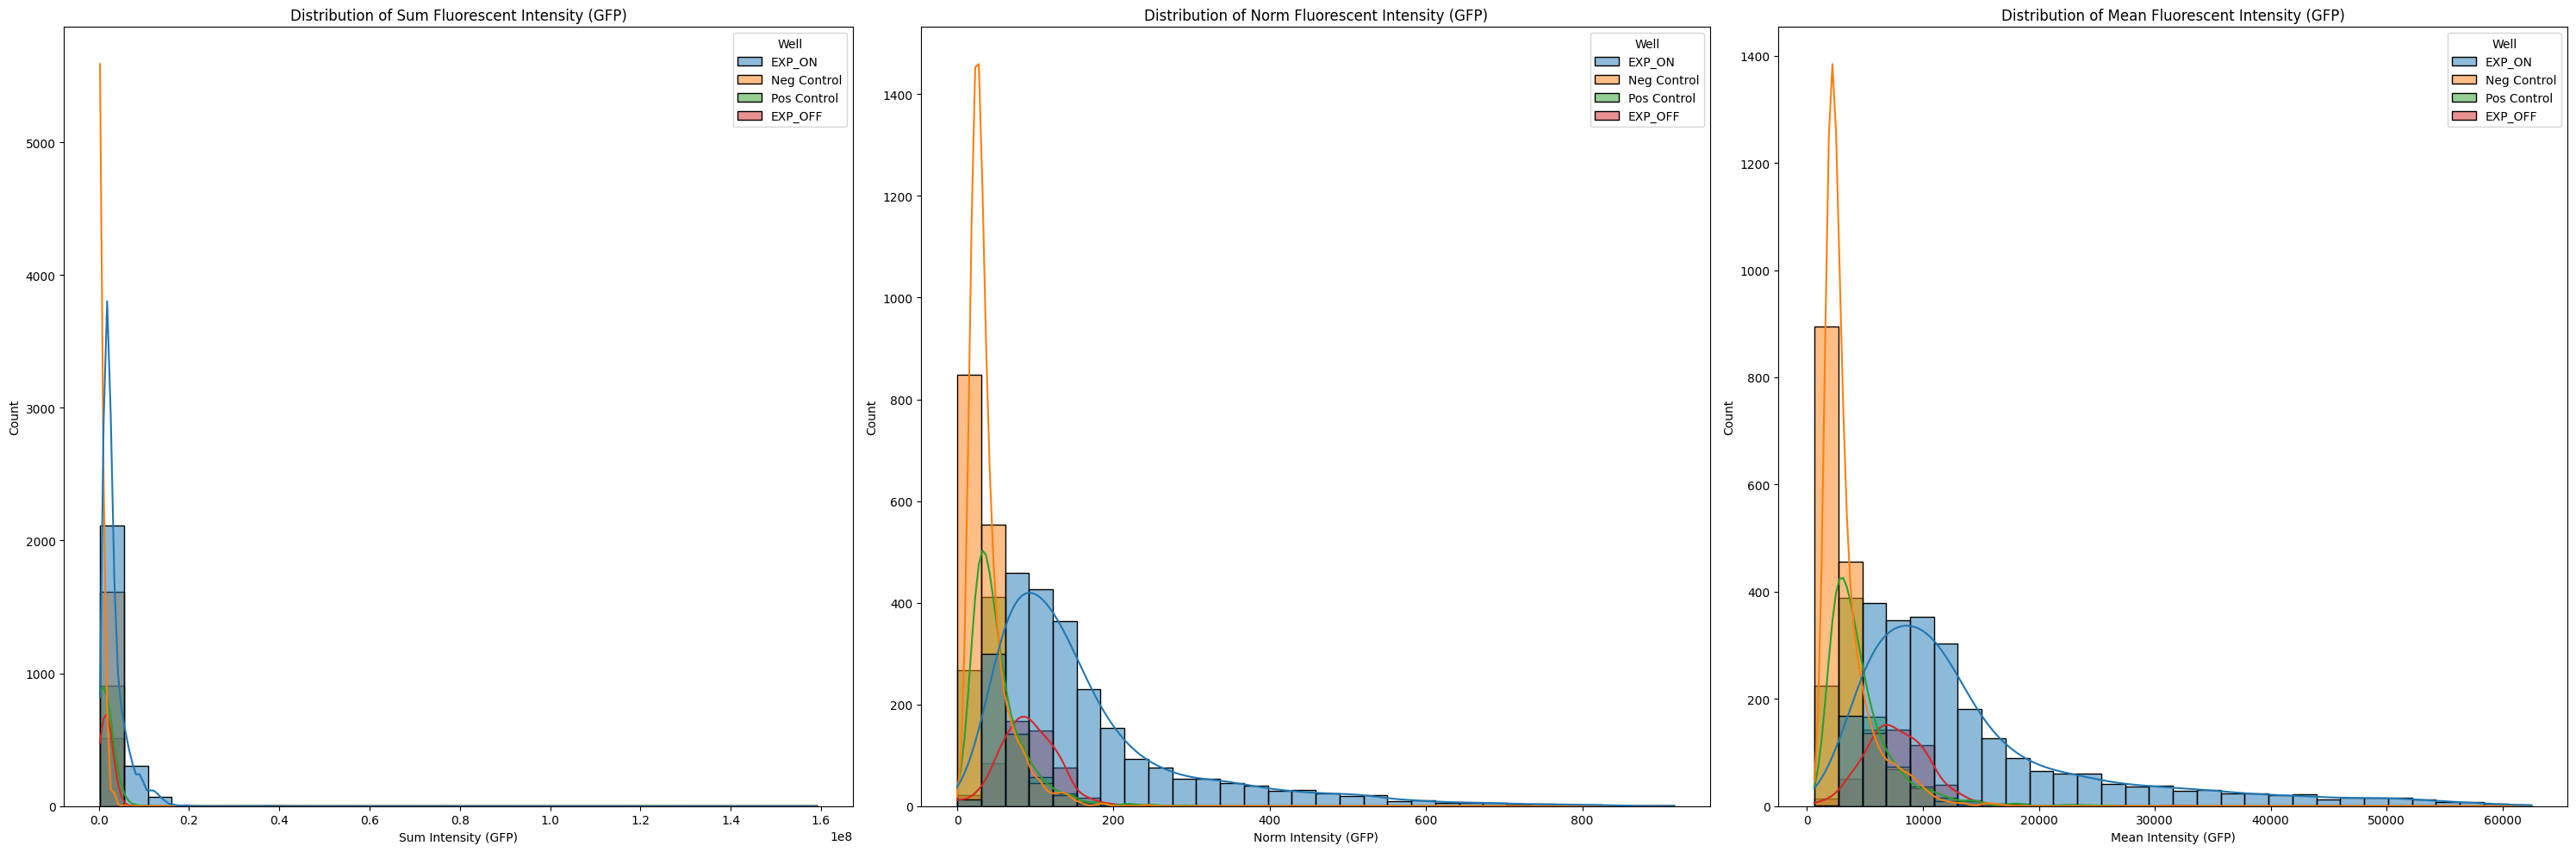

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(30, 10))

if not dye_leakage_data.empty:
    sns.histplot(data=dye_leakage_data, x='Intensity Sum (GFP)', hue='Well', kde=True, bins=30, ax=axes[0])
    axes[0].set_title('Distribution of Sum Fluorescent Intensity (GFP)')
    axes[0].set_xlabel('Sum Intensity (GFP)')
    axes[0].set_ylabel('Count')

    sns.histplot(data=dye_leakage_data, x='Intensity Norm (GFP)', hue='Well', kde=True, bins=30, ax=axes[1])
    axes[1].set_title('Distribution of Norm Fluorescent Intensity (GFP)')
    axes[1].set_xlabel('Norm Intensity (GFP)')
    axes[1].set_ylabel('Count')

    sns.histplot(data=dye_leakage_data, x='Intensity Mean (GFP)', hue='Well', kde=True, bins=30, ax=axes[2])
    axes[2].set_title('Distribution of Mean Fluorescent Intensity (GFP)')
    axes[2].set_xlabel('Mean Intensity (GFP)')
    axes[2].set_ylabel('Count')
else:
    for ax in axes:
        ax.set_visible(False) # Hide empty subplots
    plt.text(0.5, 0.5, "No data to plot. `dye_leakage_data` is empty.", horizontalalignment='center', verticalalignment='center', transform=plt.gcf().transFigure, fontsize=16, color='red')

plt.tight_layout()
plt.show()

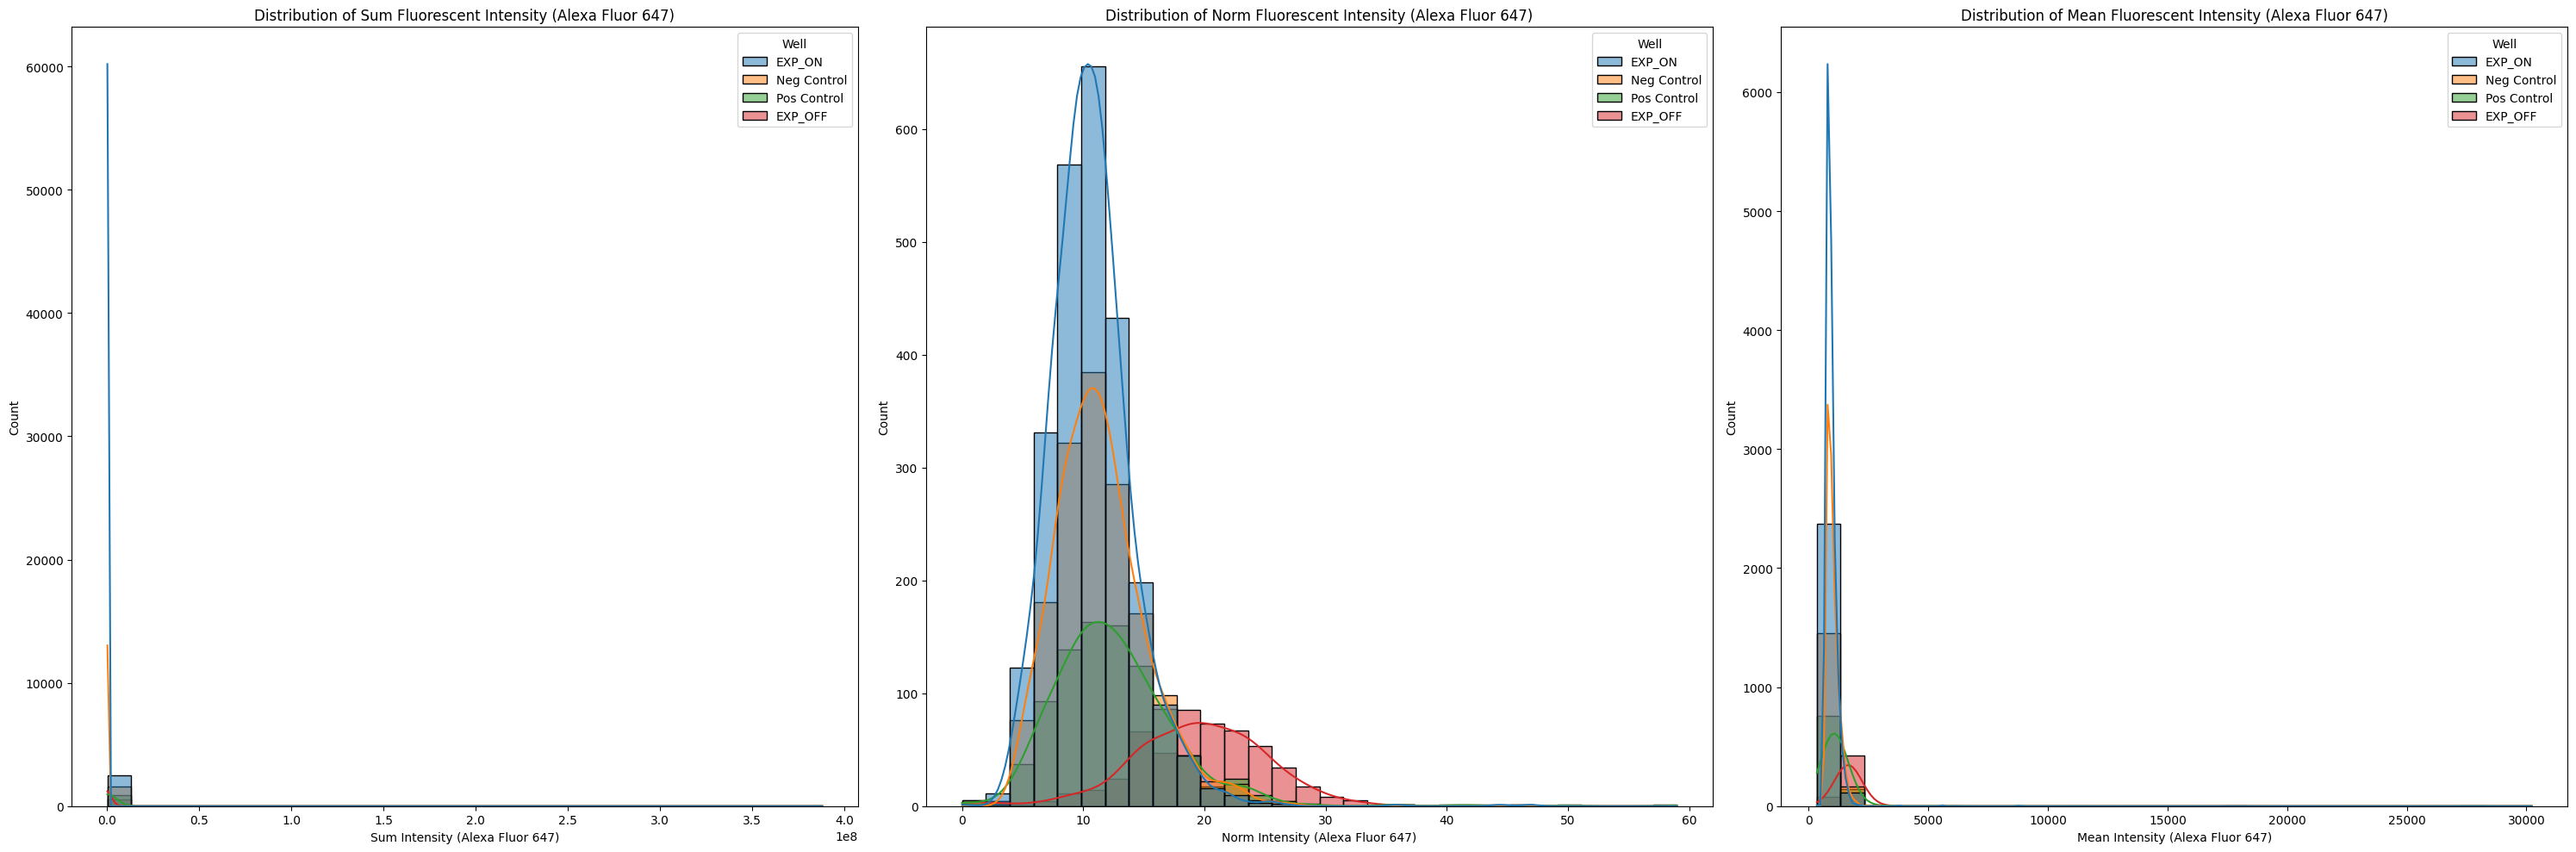

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(30, 10))

sns.histplot(data=dye_leakage_data, x='Intensity Sum (Alexa Fluor 647)', hue='Well', kde=True, bins=30, ax=axes[0])
axes[0].set_title('Distribution of Sum Fluorescent Intensity (Alexa Fluor 647)')
axes[0].set_xlabel('Sum Intensity (Alexa Fluor 647)')
axes[0].set_ylabel('Count')

sns.histplot(data=dye_leakage_data, x='Intensity Norm (Alexa Fluor 647)', hue='Well', kde=True, bins=30, ax=axes[1])
axes[1].set_title('Distribution of Norm Fluorescent Intensity (Alexa Fluor 647)')
axes[1].set_xlabel('Norm Intensity (Alexa Fluor 647)')
axes[1].set_ylabel('Count')

sns.histplot(data=dye_leakage_data, x='Intensity Mean (Alexa Fluor 647)', hue='Well', kde=True, bins=30, ax=axes[2])
axes[2].set_title('Distribution of Mean Fluorescent Intensity (Alexa Fluor 647)')
axes[2].set_xlabel('Mean Intensity (Alexa Fluor 647)')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

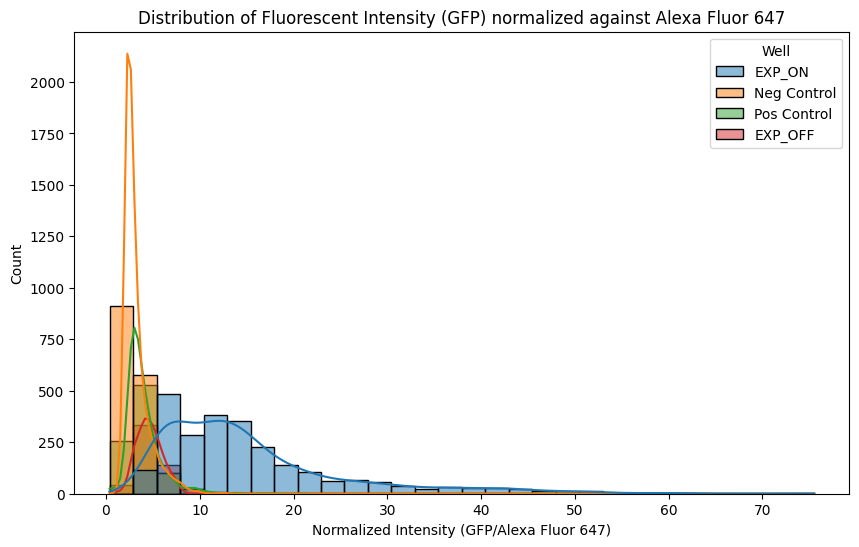

In [15]:
# Rename Well labels for legend


dye_leakage_data['Normalized Intensity (GFP)'] = dye_leakage_data['Intensity Mean (GFP)'] / dye_leakage_data['Intensity Mean (Alexa Fluor 647)']

plt.figure(figsize=(10, 6))
sns.histplot(data=dye_leakage_data, x='Normalized Intensity (GFP)', hue='Well', kde=True, bins=30)
plt.title('Distribution of Fluorescent Intensity (GFP) normalized against Alexa Fluor 647')
plt.xlabel('Normalized Intensity (GFP/Alexa Fluor 647)')
plt.ylabel('Count')
plt.show()

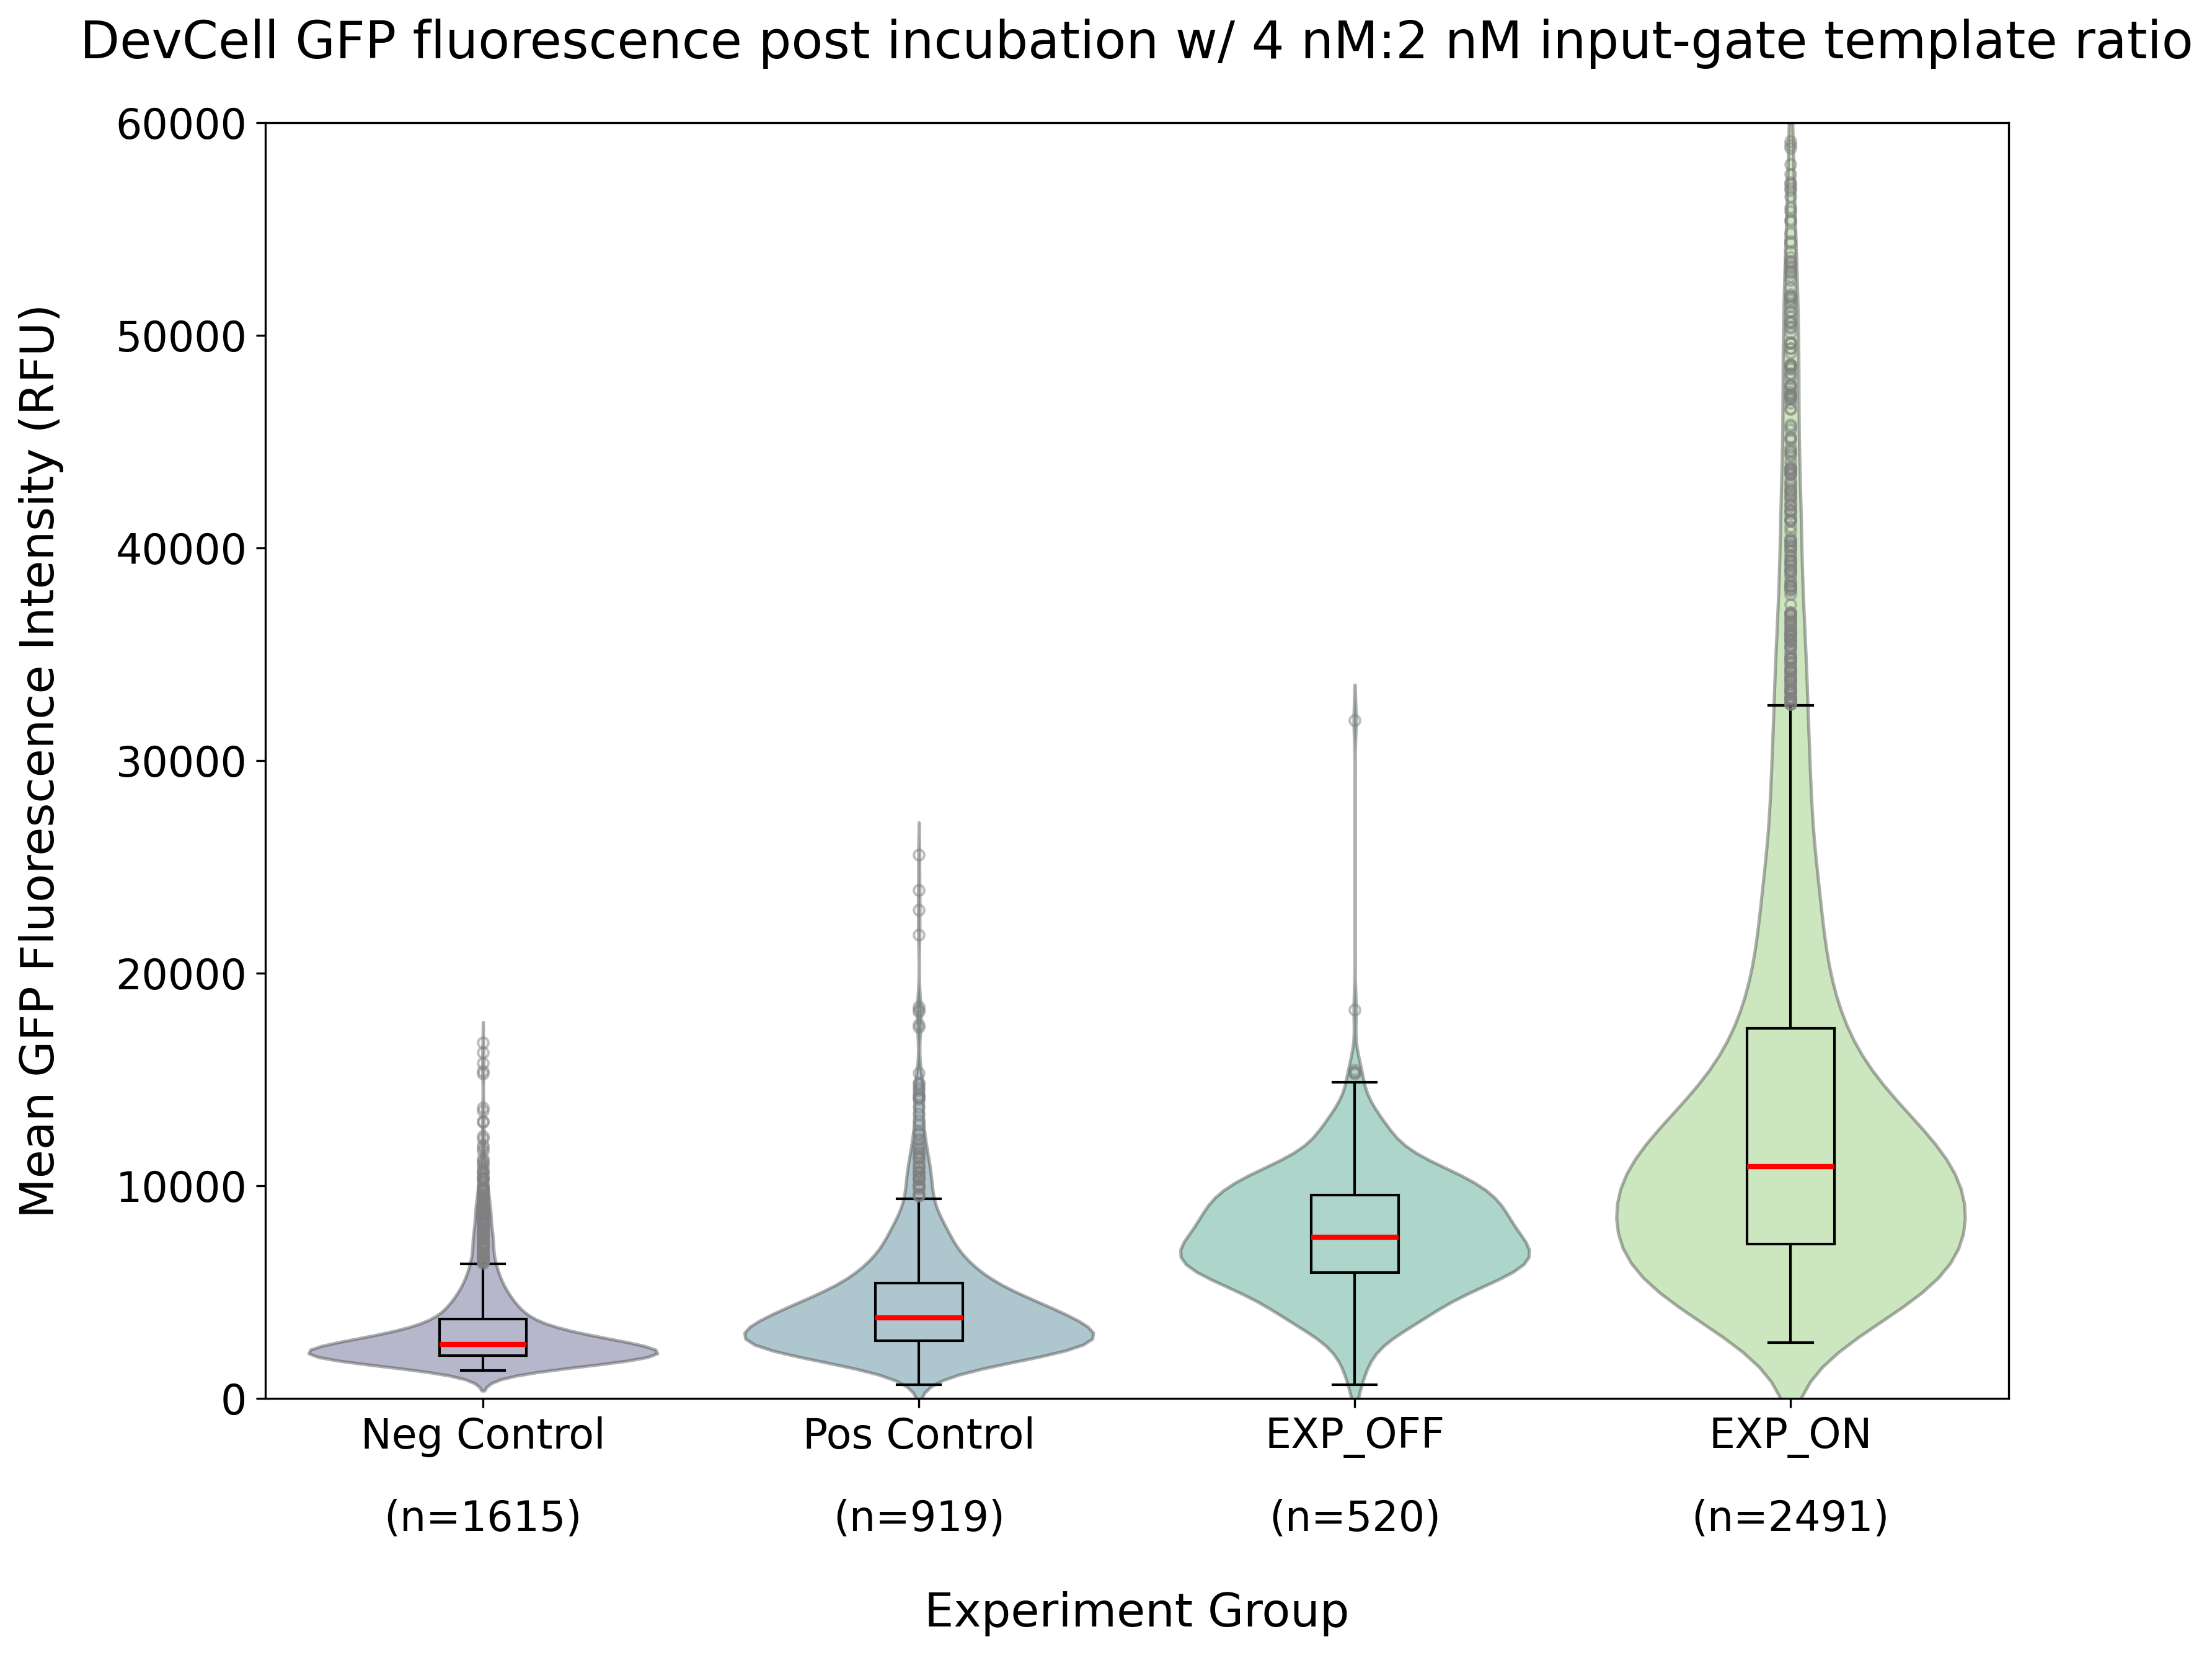

In [34]:
#| label: fig4-quantified-gfp-4nM-2nM

fig, axes = plt.subplots(1, 1, figsize=(11, 9), dpi=300)

# Define the desired order for 'Well' categories
well_order = ['Neg Control', 'Pos Control', 'EXP_OFF', 'EXP_ON']
dye_leakage_data['Well'] = pd.Categorical(dye_leakage_data['Well'], categories=well_order, ordered=True)

# Calculate group counts for the x-axis labels
counts = dye_leakage_data['Well'].value_counts()
# Add double newline characters for distinct vertical spacing
new_labels = [f"{group}\n\n(n={counts[group]})" for group in well_order]

# 1. Violin plot as the background
sns.violinplot(
    data=dye_leakage_data,
    x='Well',
    y='Intensity Mean (GFP)',
    hue='Well',
    ax=axes,
    palette='viridis',
    inner=None,
    alpha=0.4,
    legend=False
)

# 2. Box plot overlaid on top (made narrower with a distinct style)
sns.boxplot(
    data=dye_leakage_data,
    x='Well',
    y='Intensity Mean (GFP)',
    ax=axes,
    width=0.2,
    boxprops={'facecolor': 'none', 'edgecolor': 'black', 'zorder': 2},
    whiskerprops={'color': 'black', 'zorder': 2},
    capprops={'color': 'black', 'zorder': 2},
    medianprops={'color': 'red', 'linewidth': 2, 'zorder': 3},
    showfliers=True,
    flierprops={'marker': 'o', 'markersize': 4, 'markeredgecolor': 'gray', 'alpha': 0.5}
)

# Style axes
axes.set_title('DevCell GFP fluorescence post incubation w/ 4 nM:2 nM input-gate template ratio', fontsize=20, pad=25)
axes.set_xlabel('Experiment Group', fontsize=18, labelpad=20)
axes.set_ylabel('Mean GFP Fluorescence Intensity (RFU)', fontsize=18, labelpad=20)

# Apply the custom labels with larger fonts and explicit line spacing
axes.set_xticks(range(len(well_order)))
axes.set_xticklabels(new_labels, fontsize=16, linespacing=1)
axes.tick_params(axis='y', labelsize=16)
axes.set_ylim(0, 60000)

plt.tight_layout()

# Save the figure as a 300 DPI image
plt.savefig('devcell_gfp_fluorescence.png', dpi=300)
plt.show()